In [4]:
from sklearn.datasets import load_iris
import torch
from torch import nn

iris = load_iris(as_frame=False)
data = torch.tensor(iris.data)
target = torch.tensor(iris.target)
target_names = iris.target_names
print("targets:", target_names)
print("data:", data.shape)
print("targets:", target.shape)

targets: ['setosa' 'versicolor' 'virginica']
data: torch.Size([150, 4])
targets: torch.Size([150])


In [5]:
from sklearn.model_selection import train_test_split

x_train, x_test, y_train, y_test = train_test_split(
    data,
    target,
    test_size=0.2,
    stratify=target,
)

x_train = x_train.to(torch.float32)
x_test = x_test.to(torch.float32)


In [6]:
class LogisticRegression(nn.Module):
    def __init__(self):
        super().__init__()
        self.w = nn.Linear(4, 3)

    def forward(self, x):
        return self.w(x)

In [7]:
from sklearn.metrics import accuracy_score, confusion_matrix

def train(model, x, y, epochs, lr):
    model.train()
    optimizer = torch.optim.SGD(model.parameters(), lr=lr)
    loss = nn.CrossEntropyLoss()

    for _ in range(epochs):
        optimizer.zero_grad()
        pred = model(x)
        l = loss(pred, y)
        l.backward()
        optimizer.step()

def val(model, x, y):
    model.eval()
    with torch.no_grad():
        pred = model(x)
        y_pred = torch.argmax(pred, dim=1)
        acc = (y_pred == y).float().mean().item()
        print("Confusion matrix:")
        print(confusion_matrix(y, y_pred))
    return acc

In [8]:
logisticRegressionModel = LogisticRegression()

train(logisticRegressionModel, x_train, y_train, 2000, 0.01)
val(logisticRegressionModel, x_test, y_test)

Confusion matrix:
[[10  0  0]
 [ 0 10  0]
 [ 0  0 10]]


1.0

In [9]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline


X_train = x_train.detach().cpu().numpy()
X_test = x_test.detach().cpu().numpy()
Y_train = y_train.detach().cpu().numpy()
Y_test = y_test.detach().cpu().numpy()

k = 5

knn = make_pipeline(
    StandardScaler(),
    KNeighborsClassifier(n_neighbors=k),
)

knn.fit(X_train, Y_train)
y_pred = knn.predict(X_test)

print("k = " + str(k))
print(f"Test accuracy: {accuracy_score(Y_test, y_pred):.2%}")
print("Confusion matrix:")
print(confusion_matrix(Y_test, y_pred))

k = 5
Test accuracy: 96.67%
Confusion matrix:
[[10  0  0]
 [ 0 10  0]
 [ 0  1  9]]


In [10]:
from sklearn.tree import DecisionTreeClassifier
depth = 7
tree = DecisionTreeClassifier(max_depth=3)
tree.fit(X_train, Y_train)

y_pred = tree.predict(X_test)

print("depth = " + str(depth))
print(f"Test accuracy: {accuracy_score(Y_test, y_pred):.2%}")
print("Confusion matrix:")
print(confusion_matrix(Y_test, y_pred))

depth = 7
Test accuracy: 96.67%
Confusion matrix:
[[10  0  0]
 [ 0  9  1]
 [ 0  0 10]]


petal width (cm)     0.573101
petal length (cm)    0.422382
sepal length (cm)    0.004517
sepal width (cm)     0.000000
dtype: float64


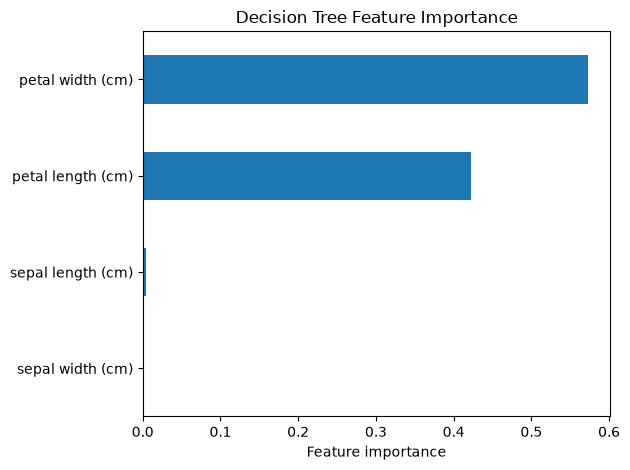

In [11]:
import pandas as pd
import matplotlib.pyplot as plt

importance = pd.Series(
    tree.feature_importances_,
    index=iris.feature_names,
).sort_values(ascending=False)

print(importance)

importance.sort_values().plot.barh()
plt.xlabel("Feature importance")
plt.title("Decision Tree Feature Importance")
plt.tight_layout()
plt.show()